# Convolutional Neural Network for Mask Detection

### Author
   * Jonathan Sancho Loaiza

## Problem Analysis (CRISP-DM 1: Business Understanding)

The question is the one a camera at the entrance of a building had to answer
during the pandemic. Given a photograph of a face, is the person wearing a mask.
People answer it at a glance but nobody can write it down as a rule made of pixel
values, which is what makes it a job for a model fitted on examples.

Masks come in many colours, fabrics and shapes, faces appear at any angle and
under any light, and the photographs were taken by different cameras at
different distances. What really separates the two classes is what covers the
lower half of the face. An uncovered face shows the edges of a nose and a mouth,
and a covered one shows a smooth region crossed by the border of the mask.

A convolutional neural network, CNN for short, is built for exactly this kind of
input. Instead of connecting every neuron to every pixel, it slides small grids
of weights called filters, or kernels, over the picture. Each filter produces a
feature map, a new image whose cells say how strongly the pattern of that filter
appears in each zone. The first layers learn simple patterns such as edges and
blobs, and the later ones combine them into larger shapes such as an eye, a
nostril or the border of a mask. That ladder from small details to whole shapes
is called the feature hierarchy, and it means nobody has to decide by hand which
measurements describe a face. The network learns them from the photographs.

The task is a binary classification. The response is the class of the photograph,
with mask or without mask, and the predictors are the pixels themselves. The model
is judged on photographs it never saw during training, by its accuracy and by the
two kinds of mistake it makes: letting an uncovered face through as covered, and
stopping a covered face as uncovered.

### Libraries

In [1]:
# Files, timing and dataset download
import os
import time
import zipfile
import importlib.util
import urllib.request

# Keras runs on TensorFlow when it is installed, as in Google Colab. On a machine
# without TensorFlow the same code runs on PyTorch instead. The backend has to be
# chosen before keras is imported
if importlib.util.find_spec('tensorflow') is None and not os.environ.get('KERAS_BACKEND'):
    os.environ['KERAS_BACKEND'] = 'torch'

# Data handling
import numpy as np
import pandas as pd

# Reading the photographs
from PIL import Image

# Plots
import matplotlib.pyplot as plt
import seaborn as sns

# The neural network
import keras
from keras import layers

# Split and evaluation
from sklearn.model_selection import train_test_split
from scipy.special import expit
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_curve, roc_auc_score)

# Where the data comes from and where it lands
DATASET_URL = ('https://gitlab.com/ejimenez/mascarilla/-/raw/main/'
               'mascarilla.zip?inline=false')
ZIP_NAME = 'mascarilla.zip'
DATA_DIR = 'Mascarilla'
IMAGE_EXTENSIONS = ('.jpg', '.jpeg', '.png')

# The two folders of the dataset and the code each one gets. The positive class,
# the one every recall and the ROC curve refer to, is the face wearing a mask
CLASS_FOLDERS = {'without_mask': 0, 'with_mask': 1}
CLASS_NAMES = ['without mask', 'with mask']

# Every photograph is read at LOAD_SIZE, in colour, and the network receives a
# crop of IMAGE_SIZE taken from it: a random one during training and the
# central one everywhere else
LOAD_SIZE = (72, 72)
IMAGE_SIZE = (64, 64)
CHANNELS = 3
PIXEL_MAX = 255.0
FLIP_CHANCE = 0.5

# Share of the photographs held out for validation and for the final test
VALIDATION_SHARE = 0.15
TEST_SHARE = 0.15

# Training settings
BATCH_SIZE = 32
FIRST_EPOCHS = 20
EXTRA_EPOCHS = 10
DROPOUT_RATE = 0.5

# The network returns logits, so accuracy compares them with 0, the logit of a
# probability of 0.5. The plain 'accuracy' metric would compare them with 0.5
LOGIT_THRESHOLD = 0.0

# Where the trained network is saved
MODEL_FILE = 'mask_cnn.keras'

# Fixed so every run gives the same split, crops and starting weights
RANDOM_STATE = 42
keras.utils.set_random_seed(RANDOM_STATE)
rng = np.random.default_rng(RANDOM_STATE)

sns.set_style('whitegrid')
print('Keras', keras.__version__, 'running on', keras.backend.backend())

Keras 3.13.2 running on tensorflow


## Data Understanding (CRISP-DM 2)

The dataset is a zip with two folders inside, one per class. The folder a
photograph sits in is its label, so there is no annotation file to join and no
photograph without a response. The cell below downloads and unpacks it only when
the folder is not already next to the notebook.

In [2]:
# The dataset is fetched only when it is not already on disk. If the folder is
# there the cell does nothing, if only the zip is there it is unpacked, and if
# neither exists the zip is downloaded first
if os.path.isdir(DATA_DIR):
    print('The folder', DATA_DIR, 'is already present, nothing is downloaded.')
else:
    if os.path.exists(ZIP_NAME):
        print('The zip is already here, only unpacking is needed.')
    else:
        print('Downloading the dataset...')
        start = time.time()
        urllib.request.urlretrieve(DATASET_URL, ZIP_NAME)
        print('Downloaded %.1f MB in %.1f seconds.'
              % (os.path.getsize(ZIP_NAME) / 1024 ** 2, time.time() - start))
    with zipfile.ZipFile(ZIP_NAME) as archive:
        archive.extractall('.')
    print('Unpacked into', DATA_DIR)

print('Folders inside', DATA_DIR + ':', sorted(os.listdir(DATA_DIR)))

Downloaded 163.1 MB in 1.8 seconds.
Unpacked into Mascarilla
Folders inside Mascarilla: ['with_mask', 'without_mask']


The message printed says which of the three situations the cell found: the folder
already unpacked, the zip present but not unpacked, or neither, in which case it
downloaded the file. The listing at the end confirms the two folders that carry
the labels.

Photographs in total: 7553

              Photographs  Share %
folder                            
with_mask            3725     49.3
without_mask         3828     50.7


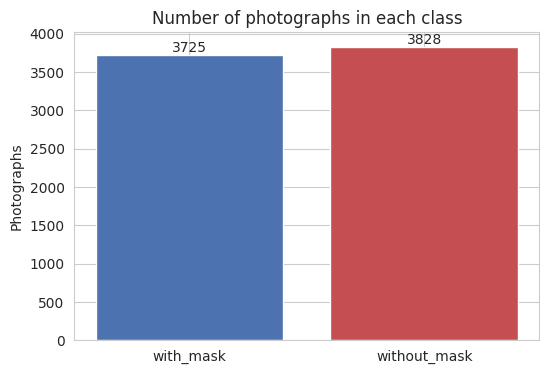

In [3]:
# One row per photograph, with the label its folder gives
records = []
for folder, label in CLASS_FOLDERS.items():
    folder_path = os.path.join(DATA_DIR, folder)
    for name in sorted(os.listdir(folder_path)):
        if name.lower().endswith(IMAGE_EXTENSIONS):
            records.append({'path': os.path.join(folder_path, name),
                            'folder': folder,
                            'label': label})

faces = pd.DataFrame(records)
print('Photographs in total:', len(faces))
print()
counts = faces['folder'].value_counts().sort_index()
share = (faces['folder'].value_counts(normalize=True).sort_index() * 100).round(1)
print(pd.DataFrame({'Photographs': counts.values, 'Share %': share.values},
                   index=counts.index))

# Bar chart of the two classes
plt.figure(figsize=(6, 4))
bars = plt.bar(counts.index, counts.values, color=['#4c72b0', '#c44e52'])
for bar, value in zip(bars, counts.values):
    plt.text(bar.get_x() + bar.get_width() / 2, value, str(value),
             ha='center', va='bottom')
plt.title('Number of photographs in each class')
plt.ylabel('Photographs')
plt.show()

The table gives, for each folder, how many photographs it holds and what share of
the collection that is, and the bar chart draws the same counts so the two
classes can be compared at a glance.

The collection holds 7553 photographs, 3828 without a mask and 3725 with one, so
the two classes weigh 50.7 and 49.3 percent. A model that ignored the picture and
always answered the larger class would be right about half the time, and that is
the floor every later result has to clear. Because the classes are this close in
size, accuracy is a fair summary of the problem, which it would not be on a
collection where one class held nine tenths of the photographs.

        width  height
count  7553.0  7553.0
mean    259.6   268.9
std     274.9   257.7
min      26.0    37.0
25%     150.0   144.0
50%     204.0   225.0
75%     275.0   275.0
max    5760.0  5412.0

Colour modes found:
mode
RGB     7544
RGBA       5
P          4
Name: count, dtype: int64


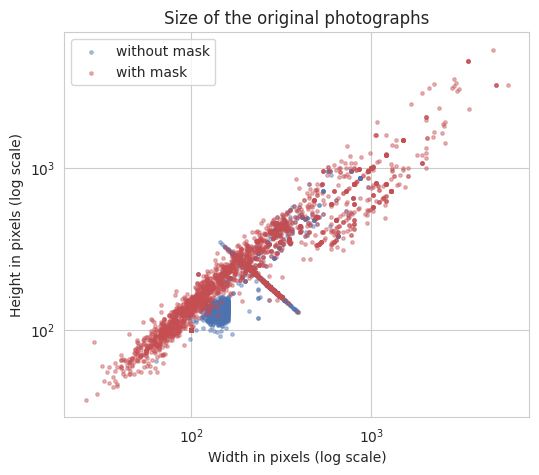

In [4]:
# Width, height and colour mode of every file, read from the header only
widths, heights, modes = [], [], []
for path in faces['path']:
    with Image.open(path) as handle:
        width, height = handle.size
        modes.append(handle.mode)
    widths.append(width)
    heights.append(height)

faces['width'] = widths
faces['height'] = heights
faces['mode'] = modes
print(faces[['width', 'height']].describe().round(1))
print()
print('Colour modes found:')
print(faces['mode'].value_counts())

# Width against height, one dot per photograph, on a log scale because a few
# files are many times larger than the rest
plt.figure(figsize=(6, 5))
for folder, colour in zip(CLASS_FOLDERS, ['#4c72b0', '#c44e52']):
    subset = faces[faces['folder'] == folder]
    plt.scatter(subset['width'], subset['height'], s=6, alpha=0.4,
                color=colour, label=folder.replace('_', ' '))
plt.xscale('log')
plt.yscale('log')
plt.xlabel('Width in pixels (log scale)')
plt.ylabel('Height in pixels (log scale)')
plt.title('Size of the original photographs')
plt.legend()
plt.show()

The table describes the width and height of the files as they come: count, mean,
standard deviation, minimum, the three quartiles and the maximum. The colour mode
says how each file stores its pixels. RGB is a colour image with three channels,
one matrix each for red, green and blue, L is a grey image with a single channel,
and RGBA or P are colour images stored in other ways. The scatter places one dot
per photograph at its width and height, on axes where every step doubles the
size, so dots on the diagonal are square pictures and dots away from it are wide
or tall ones.

The sizes vary enormously. Half the photographs sit between 150 and 275 pixels
wide, with a median of 204 by 225, but the smallest file is 26 by 37 and the
largest 5760 by 5412. Almost every file is RGB, 7544 of them, and the 9 stored as
RGBA or P are converted to RGB when they are read, so every photograph enters the
network with three channels.

The scatter also shows that the two classes do not come from the same kind of
source. Many uncovered faces form a tight block between roughly 100 and 160
pixels on each side, while the covered ones spread along the whole diagonal and
include a straight line of red dots that looks like a batch of files resized
the same way. Once every picture is shrunk to 72 by 72 the size itself is gone,
but the sharpness is not: a small file blown up looks blurrier than a large one
shrunk. This is a reminder that a network fed these pictures could pick up traits
of the source alongside the mask, and nothing in this notebook rules that out.

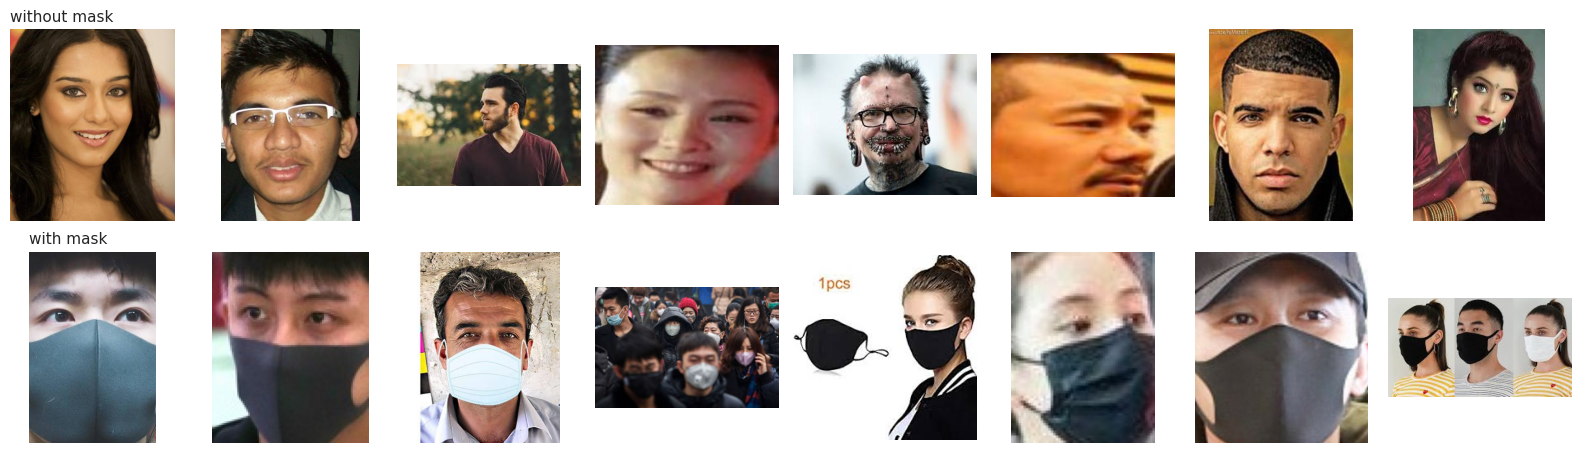

In [5]:
# Eight photographs of each class, straight from the files
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for row, folder in enumerate(CLASS_FOLDERS):
    chosen = faces[faces['folder'] == folder].sample(8, random_state=RANDOM_STATE)
    for ax, path in zip(axes[row], chosen['path']):
        with Image.open(path) as handle:
            ax.imshow(handle.convert('RGB'))
        ax.axis('off')
    axes[row][0].set_title(folder.replace('_', ' '), loc='left', fontsize=11)
plt.tight_layout()
plt.show()

The grid shows eight photographs of each class exactly as they sit in the files,
the uncovered faces in the top row and the covered ones in the bottom row.

The variety is large. Faces appear close up and far away, alone and in crowds,
some covered faces sit next to a product shot of the mask itself, and one picture
shows three people side by side. Nothing about framing or background separates
the classes reliably, so what the network has to find is what covers the lower
half of the face: masks of any colour, from black cloth to light blue surgical
ones, against the nose and mouth of the uncovered faces.

## Data Exploration (CRISP-DM 2) and Data Preparation (CRISP-DM 3)

A CNN needs every input to have the same shape, so each photograph is converted
to colour and resized to 72 by 72 pixels, a little larger than the 64 by 64 the
network receives, so there is room to cut a crop out of it later. The result is
a tensor, a table of numbers with any number of dimensions. One photograph
becomes a tensor of 72 x 72 x 3, a stack of three matrices, one per colour
channel, and the whole collection becomes a tensor of four dimensions:
photographs, height, width and channels. The pixels are kept as whole numbers
from 0 to 255 to save memory, and are divided by 255 only when a batch is handed
to the network.

In [6]:
# One photograph becomes a 72 x 72 colour array of whole numbers from 0 to 255
def load_image(path):
    """Read a file as an RGB array of LOAD_SIZE."""
    with Image.open(path) as handle:
        # Large JPEG files are decoded at a reduced scale first, which is much
        # faster and gives the same picture once it is shrunk to 72 x 72
        handle.draft('RGB', (LOAD_SIZE[0] * 2, LOAD_SIZE[1] * 2))
        # Palette files may carry transparency, which is read through RGBA
        image = handle.convert('RGBA') if handle.mode == 'P' else handle
        resized = image.convert('RGB').resize(LOAD_SIZE, Image.BILINEAR)
    return np.asarray(resized, dtype=np.uint8)


# Every photograph of the collection is read, none is left out
start = time.time()
images = np.empty((len(faces), LOAD_SIZE[1], LOAD_SIZE[0], CHANNELS),
                  dtype=np.uint8)
for position, path in enumerate(faces['path']):
    images[position] = load_image(path)
labels = faces['label'].to_numpy(dtype=np.int8)

print('Read %d photographs in %.1f seconds.' % (len(images), time.time() - start))
print('Shape of the image tensor:', images.shape)
print('Shape of the label vector:', labels.shape)
print('Memory used by the images: %.1f MB' % (images.nbytes / 1024 ** 2))

Read 7553 photographs in 10.7 seconds.
Shape of the image tensor: (7553, 72, 72, 3)
Shape of the label vector: (7553,)
Memory used by the images: 112.0 MB


The shape of the image tensor reads as photographs, height, width and channels,
which is the order Keras expects: 7553 photographs of 72 by 72 pixels with 3
channels each. The label vector holds one 0 or 1 per photograph, 0 for without
mask and 1 for with mask. Stored as whole numbers from 0 to 255 the whole
collection takes 112 MB of memory, so every photograph is kept and none had to be
left out to fit.

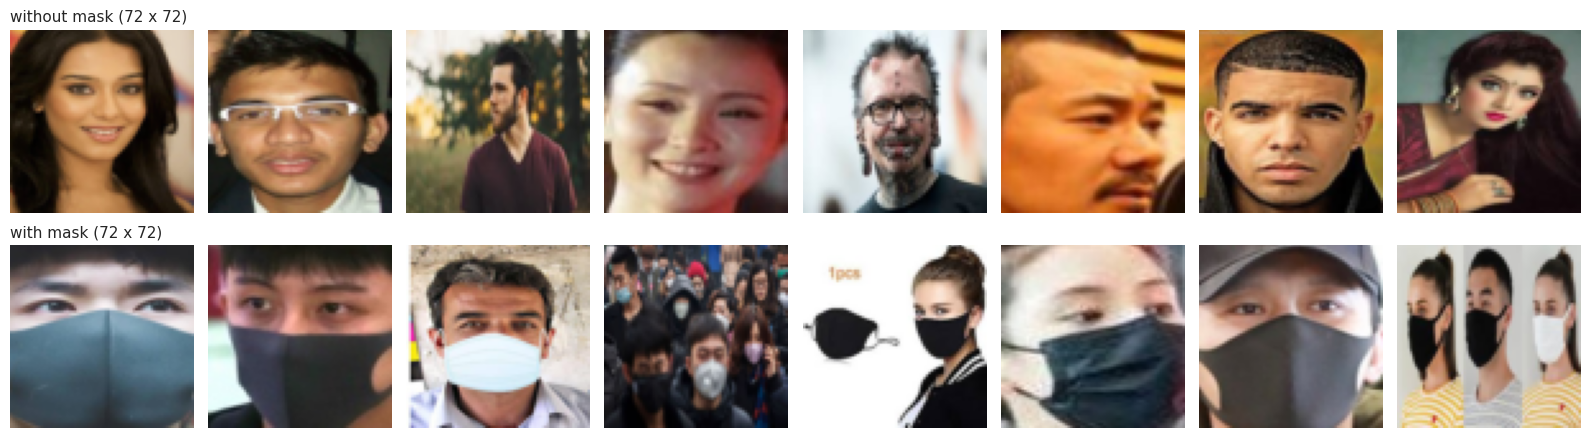

In [7]:
# The same sixteen photographs after shrinking them to 72 x 72
fig, axes = plt.subplots(2, 8, figsize=(16, 4.6))
for row, folder in enumerate(CLASS_FOLDERS):
    chosen = faces[faces['folder'] == folder].sample(8, random_state=RANDOM_STATE)
    for ax, position in zip(axes[row], chosen.index):
        ax.imshow(images[position])
        ax.axis('off')
    axes[row][0].set_title(folder.replace('_', ' ') + ' (72 x 72)',
                           loc='left', fontsize=11)
plt.tight_layout()
plt.show()

These are the same sixteen photographs as before, now at the size they are kept
in memory. Each picture has only 5184 pixels, so this grid is the honest view of
how much detail is left to tell the classes apart.

The faces stay recognisable and so do the masks: the black and light blue
patches over the lower face are still obvious at this size. What is lost is the
fine detail of the small faces in the crowd picture, where each face is now a
handful of pixels, and those are the photographs to expect among the mistakes.

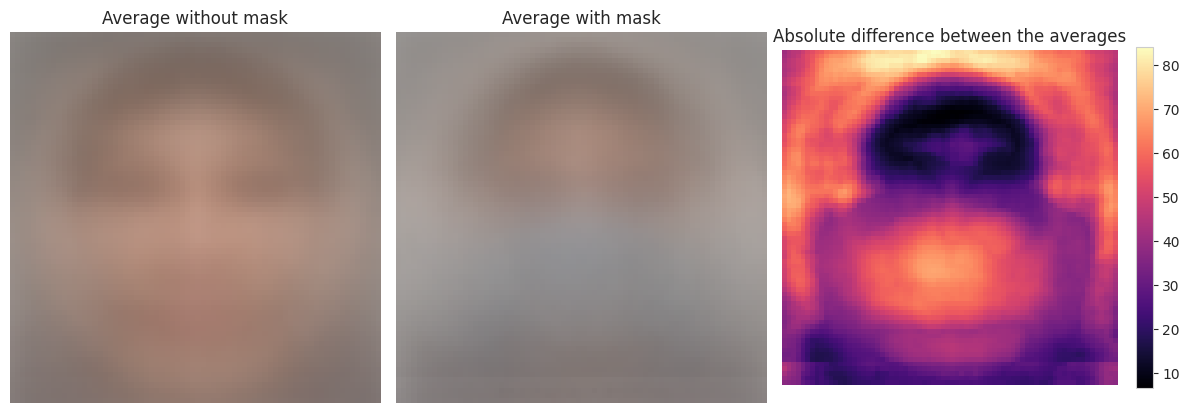

In [8]:
# The average photograph of each class, pixel by pixel
fig, axes = plt.subplots(1, 3, figsize=(12, 4.2))
means = {}
for ax, (folder, label) in zip(axes, CLASS_FOLDERS.items()):
    means[label] = images[labels == label].mean(axis=0)
    ax.imshow(means[label].astype(np.uint8))
    ax.set_title('Average ' + CLASS_NAMES[label])
    ax.axis('off')

# Where the two averages differ the most, summed over the three channels
difference = np.abs(means[1] - means[0]).sum(axis=2)
shown = axes[2].imshow(difference, cmap='magma')
axes[2].set_title('Absolute difference between the averages')
axes[2].axis('off')
fig.colorbar(shown, ax=axes[2], fraction=0.046)
plt.tight_layout()
plt.show()

The first two panels are the average photograph of each class: every pixel is
the mean of that pixel over all the photographs of the class, so whatever sits
in the same place in most pictures stays sharp and whatever moves around blurs
away. The third panel shows, for each pixel, how far apart the two averages are,
with dark meaning the classes look the same there and bright meaning they differ.
The scale on its right runs from about 10 to 85, out of the 765 that would
separate pure black from pure white on all three channels.

Both averages show a blurred face centred in the frame, which means most
photographs are cropped around the face. The uncovered average has skin tones
around the mouth while the covered one turns grey and bluish in the lower half,
which is the colour of the typical surgical mask. The difference map agrees: the
eyes and forehead are the darkest band, near 10, because both classes show them,
and the area of the nose and mouth is one of the brightest, near 70. The top
edge of the frame is also bright, close to 80, so the backgrounds and hair above
the face differ between the two classes too. That is the same warning as the
size scatter: part of what separates the classes in these files is not the mask.

In [9]:
# A fixed split in three parts, stratified so each part keeps the class balance.
# The test photographs are set aside first and are not touched until evaluation
holdout = VALIDATION_SHARE + TEST_SHARE
x_train, x_rest, y_train, y_rest = train_test_split(
    images, labels, test_size=holdout, stratify=labels, random_state=RANDOM_STATE)
x_valid, x_test, y_valid, y_test = train_test_split(
    x_rest, y_rest, test_size=TEST_SHARE / holdout, stratify=y_rest,
    random_state=RANDOM_STATE)
del x_rest, y_rest

split_table = pd.DataFrame({
    'Photographs': [len(y_train), len(y_valid), len(y_test)],
    'With mask %': [100 * y.mean() for y in (y_train, y_valid, y_test)],
}, index=['train', 'validation', 'test']).round(1)
print(split_table)

            Photographs  With mask %
train              5287         49.3
validation         1133         49.3
test               1133         49.3


The training part is what the network learns from. The validation part is
measured after every epoch, one full pass over the training photographs, to
watch whether the network keeps improving on pictures it does not learn from.
The test part is used once, at the end, to report the final result. The split
is done once and kept fixed, so no photograph moves from one part to another
between epochs, which would let the network be validated on pictures it already
trained on. The last column checks that the three parts keep the same share of
covered faces.

The split gives 5287 training photographs and 1133 each for validation and test,
and the three parts hold exactly the same share of covered faces, 49.3 percent,
so a difference in score between them cannot come from a different class mix.

The training photographs get data augmentation. Every time a photograph enters a
batch it is slightly changed at random: a random 64 by 64 crop is cut out of the
72 by 72 picture, which shifts the face a few pixels in any direction, and the
crop is flipped left to right half of the time. A face shifted or mirrored is
still the same face with the same label, so the network gets a new example for
free and has a harder time memorising single pictures. The changes happen only
during training. Validation and test photographs always get the central crop and
nothing random, so their scores can be compared from one epoch to the next.

In [10]:
# Turn a batch of stored photographs into network input. In training mode each
# photograph gets a random crop and a random horizontal flip, in eval mode the
# central crop. Both divide the pixels by 255
def preprocess(batch, mode='train'):
    """Crop, maybe flip and scale a batch of LOAD_SIZE photographs."""
    count = len(batch)
    room_y = LOAD_SIZE[1] - IMAGE_SIZE[1]
    room_x = LOAD_SIZE[0] - IMAGE_SIZE[0]
    if mode == 'train':
        tops = rng.integers(0, room_y + 1, size=count)
        lefts = rng.integers(0, room_x + 1, size=count)
    else:
        tops = np.full(count, room_y // 2)
        lefts = np.full(count, room_x // 2)
    out = np.empty((count, IMAGE_SIZE[1], IMAGE_SIZE[0], CHANNELS), dtype=np.float32)
    for i in range(count):
        crop = batch[i, tops[i]:tops[i] + IMAGE_SIZE[1], lefts[i]:lefts[i] + IMAGE_SIZE[0]]
        if mode == 'train' and rng.random() < FLIP_CHANCE:
            crop = crop[:, ::-1]
        out[i] = crop
    return out / PIXEL_MAX


# Feeds the network one batch at a time, so every epoch sees new random crops
# and flips, and shuffles the training photographs after each epoch
class FaceBatches(keras.utils.PyDataset):
    def __init__(self, x, y, mode, **kwargs):
        super().__init__(**kwargs)
        self.x, self.y, self.mode = x, y, mode
        self.order = np.arange(len(x))
        self.on_epoch_end()

    def __len__(self):
        return int(np.ceil(len(self.x) / BATCH_SIZE))

    def __getitem__(self, index):
        chosen = self.order[index * BATCH_SIZE:(index + 1) * BATCH_SIZE]
        return preprocess(self.x[chosen], self.mode), self.y[chosen].astype(np.float32)

    def on_epoch_end(self):
        if self.mode == 'train':
            rng.shuffle(self.order)


ds_train = FaceBatches(x_train, y_train, mode='train')
ds_valid = FaceBatches(x_valid, y_valid, mode='eval')
print('Batches per epoch, training:  ', len(ds_train))
print('Batches per epoch, validation:', len(ds_valid))

Batches per epoch, training:   166
Batches per epoch, validation: 36


The two numbers are how many batches of 32 photographs make up one epoch, one
full pass over each part. The validation batches are not shuffled and carry no
randomness, so every epoch measures exactly the same 1133 pictures.

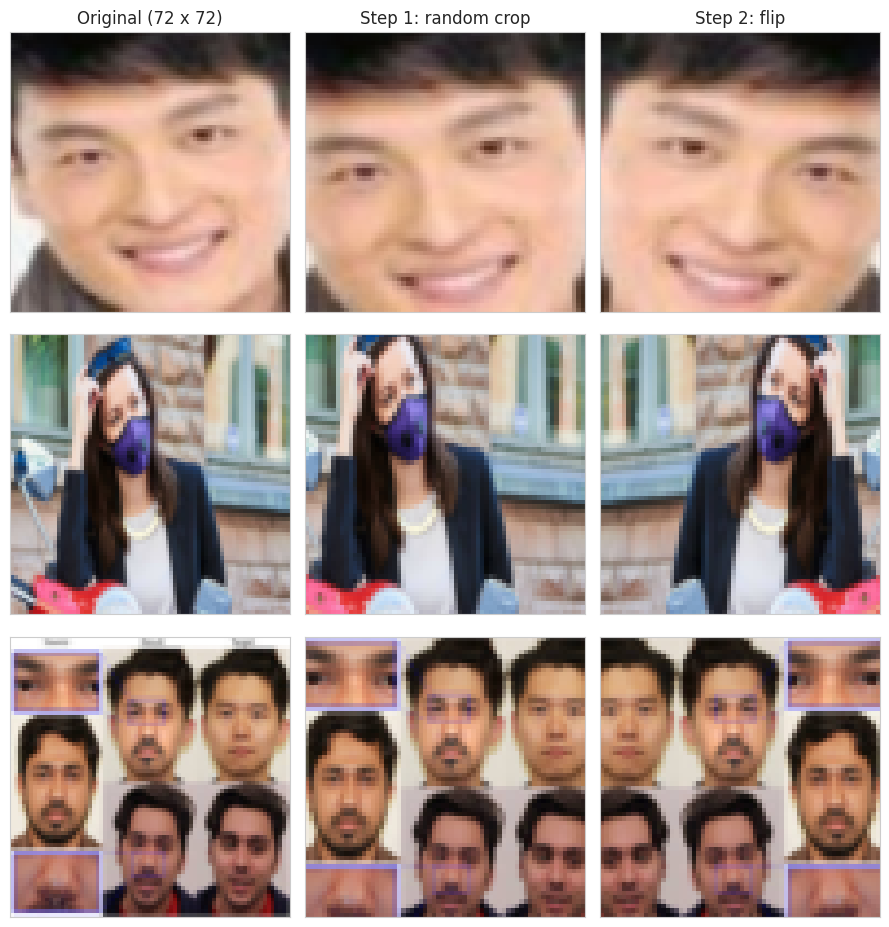

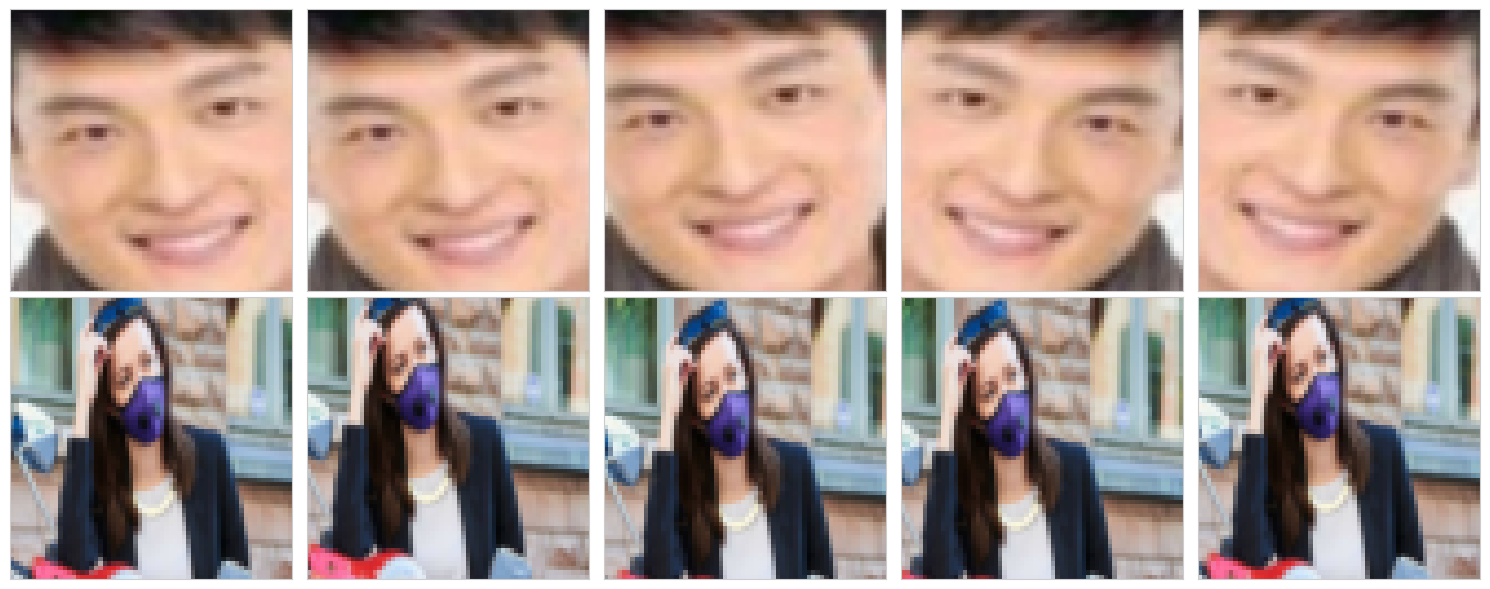

In [11]:
# Three training photographs and the two steps of the training transformation
fig, axes = plt.subplots(3, 3, figsize=(9, 9.5))
for row in range(3):
    original = x_train[row:row + 1]
    top = rng.integers(0, LOAD_SIZE[1] - IMAGE_SIZE[1] + 1)
    left = rng.integers(0, LOAD_SIZE[0] - IMAGE_SIZE[0] + 1)
    cropped = original[0, top:top + IMAGE_SIZE[1], left:left + IMAGE_SIZE[0]]
    axes[row][0].imshow(original[0])
    axes[row][1].imshow(cropped)
    axes[row][2].imshow(cropped[:, ::-1])
titles = ['Original (72 x 72)', 'Step 1: random crop', 'Step 2: flip']
for ax, title in zip(axes[0], titles):
    ax.set_title(title)
for ax in axes.ravel():
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

# Two training photographs, each passed five times through the training mode
fig, axes = plt.subplots(2, 5, figsize=(15, 6))
for row in range(2):
    for ax in axes[row]:
        ax.imshow(preprocess(x_train[row:row + 1], mode='train')[0])
        ax.set_xticks([])
        ax.set_yticks([])
plt.tight_layout()
plt.show()

In the first figure each row follows one training photograph through the two
steps: the stored 72 by 72 picture, the 64 by 64 crop cut at a random place, and
the same crop mirrored. The second figure passes two photographs through the
training mode five times each, which is what the network may receive in their
place on five different epochs.

The crop removes a thin band of the frame and makes the face look a little
larger, and the flip moves everything to the opposite side, as the raised arm in
the second row shows. In every version the mask stays where it was on the face,
so the label is still right, and that is the condition that makes these changes
safe to use.

## Machine Learning Model (CRISP-DM 4: Modeling)

The network is a CNN of four convolutional blocks followed by global average
pooling and a single output neuron. A convolutional block is the package of a
convolution, which slides its kernels over the input and produces feature maps,
the ReLU activation, which turns every negative value into zero, and max pooling,
which shrinks each feature map by keeping only the largest number of every
2 x 2 square. Pooling has no weights, so it learns nothing, it only summarises.

Dropout switches off a random half of the outputs of a layer at every training
step, so no neuron can rely on one particular partner, which works against
overfitting. The model is built in steps below, checking the shape of what comes
out after each one.

In [12]:
# The convolutional part: four blocks of 3 x 3 kernels, 32, 64, 128 and 256 of them
mask_cnn = keras.Sequential([
    layers.Conv2D(32, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(rate=DROPOUT_RATE),

    layers.Conv2D(64, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Dropout(rate=DROPOUT_RATE),

    layers.Conv2D(128, (3, 3), padding='same', activation='relu'),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(256, (3, 3), padding='same', activation='relu'),
], name='mask_cnn')

input_shape = (None, IMAGE_SIZE[1], IMAGE_SIZE[0], CHANNELS)
print('Output of the convolutional part:', mask_cnn.compute_output_shape(input_shape))

Output of the convolutional part: (None, 8, 8, 256)


The shape reads as photographs in the batch, height, width and feature maps,
with None standing for a batch of any size. The padding called same adds a border
of zeros so each convolution keeps the size of its input, and each of the three
max poolings halves it, from 64 to 32, 16 and 8, so the last convolution leaves
256 feature maps of 8 by 8 for every photograph.

In [13]:
# Global average pooling turns each of the 256 feature maps into its average
mask_cnn.add(layers.GlobalAveragePooling2D())
print('Output after global average pooling:', mask_cnn.compute_output_shape(input_shape))

Output after global average pooling: (None, 256)


Global average pooling replaces each feature map by a single number, its
average, so each photograph is now described by 256 numbers instead of
8 x 8 x 256 = 16384. The output neuron added next receives those 256 numbers.

In [14]:
# One output neuron with no activation, so it returns a logit
mask_cnn.add(layers.Dense(1, activation=None))

mask_cnn.build(input_shape=input_shape)
mask_cnn.summary()

Model: "mask_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 64, 64, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32, 32, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 16, 16, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 8, 8, 256)      │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 388,673 (1.48 MB)

 Trainable params: 388,673 (1.48 MB)

 Non-trainable params: 0 (0.00 B)

The last layer has no activation and returns a logit, a number of any size that
becomes a probability once it passes through the sigmoid function. A logit of 0
is a probability of 0.5, a positive logit means more likely with a mask and a
negative one more likely without.

The summary lists the layers in order. For each one, the output shape says what
leaves it and the parameter count says how many weights it learns. A convolution
of 3 x 3 kernels learns 3 x 3 x input channels weights plus one bias per kernel,
so the first one has 3 x 3 x 3 x 32 + 32 = 896, and the output neuron has 256
weights plus one bias, 257. The pooling and dropout layers show 0 parameters
because they learn nothing.

The network learns 388673 numbers in total, all of them trainable. The last
convolution alone holds 295168 of them, three quarters of the total, because it
has the most kernels and each one spans the 128 maps that enter it. The output
neuron needs only 257 thanks to global average pooling. Flattening the 8 x 8 x 256
maps instead would have given it 16385.

In [15]:
# Binary cross-entropy computed from the logits, Adam optimizer, and accuracy
# read with the logit threshold of 0
mask_cnn.compile(optimizer=keras.optimizers.Adam(),
                 loss=keras.losses.BinaryCrossentropy(from_logits=True),
                 metrics=[keras.metrics.BinaryAccuracy(name='accuracy',
                                                       threshold=LOGIT_THRESHOLD)])

In [16]:
# First round of training, validated on the fixed validation photographs
start = time.time()
history = mask_cnn.fit(ds_train,
                       validation_data=ds_valid,
                       epochs=FIRST_EPOCHS,
                       verbose=2)
print('Training took %.1f minutes.' % ((time.time() - start) / 60))

Epoch 1/20
166/166 - 23s - 139ms/step - accuracy: 0.7267 - loss: 0.5348 - val_accuracy: 0.7396 - val_loss: 0.4968
Epoch 2/20
166/166 - 2s - 10ms/step - accuracy: 0.8668 - loss: 0.3185 - val_accuracy: 0.9188 - val_loss: 0.2327
Epoch 3/20
166/166 - 2s - 9ms/step - accuracy: 0.9013 - loss: 0.2431 - val_accuracy: 0.9197 - val_loss: 0.1947
Epoch 4/20
166/166 - 1s - 9ms/step - accuracy: 0.9058 - loss: 0.2320 - val_accuracy: 0.9294 - val_loss: 0.1888
Epoch 5/20
166/166 - 2s - 9ms/step - accuracy: 0.9158 - loss: 0.2042 - val_accuracy: 0.9082 - val_loss: 0.2294
Epoch 6/20
166/166 - 2s - 12ms/step - accuracy: 0.9200 - loss: 0.1992 - val_accuracy: 0.9329 - val_loss: 0.1740
Epoch 7/20
166/166 - 2s - 11ms/step - accuracy: 0.9264 - loss: 0.1824 - val_accuracy: 0.9320 - val_loss: 0.1734
Epoch 8/20
166/166 - 1s - 9ms/step - accuracy: 0.9277 - loss: 0.1827 - val_accuracy: 0.9170 - val_loss: 0.2071
Epoch 9/20
166/166 - 2s - 9ms/step - accuracy: 0.9349 - loss: 0.1698 - val_accuracy: 0.9550 - val_loss: 0.

Each line is one epoch. The loss is the binary cross-entropy, the average
penalty for the probabilities given to the correct class, which is near 0 when
the network gives the right class a probability close to 1 and grows fast when
it is confident and wrong. The accuracy is the share of photographs classified
correctly. The columns without a prefix are measured on the training photographs
during the epoch, and the ones that start with val are measured afterwards on the
validation photographs.

The network starts at 0.7396 of validation accuracy after one epoch and is
already above 0.90 after the second. By epoch 20 it reaches 0.9599 on training and
0.9673 on validation, with losses of 0.1143 and 0.0974. The first epoch takes
longer than the rest because the computation is prepared the first time it runs.

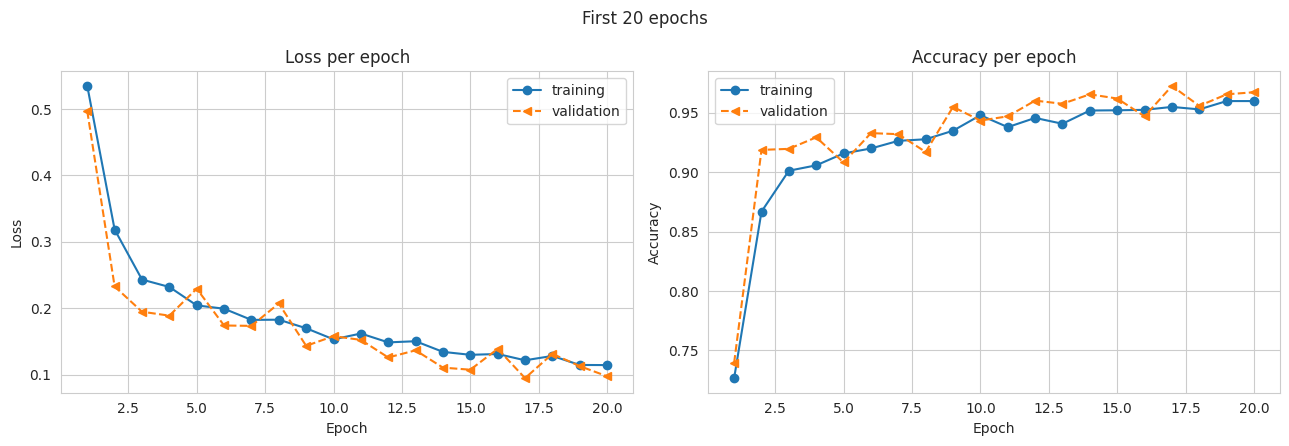

In [17]:
# Loss and accuracy of every epoch, on training and on validation
def plot_history(records, title):
    """Draw the loss and accuracy curves of a training history."""
    epochs = np.arange(1, len(records['loss']) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    for ax, metric in zip(axes, ['loss', 'accuracy']):
        ax.plot(epochs, records[metric], '-o', label='training')
        ax.plot(epochs, records['val_' + metric], '--<', label='validation')
        ax.set_xlabel('Epoch')
        ax.set_ylabel(metric.capitalize())
        ax.set_title(metric.capitalize() + ' per epoch')
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_history(history.history, 'First %d epochs' % FIRST_EPOCHS)

The left panel draws the loss of every epoch and the right one the accuracy, in
blue on the training photographs and in orange on the validation ones. Falling
loss and rising accuracy mean the network is still learning. A validation curve
that turns upward in loss while the training one keeps falling is the sign of
overfitting, the network memorising the training pictures. A validation score
better than the training one is not an error here: during training half the
outputs of two layers are switched off by dropout and the photographs are
randomly cropped and flipped, while validation uses the whole network on the
central crop.

Both curves fall together and there is no sign of overfitting: validation
accuracy is above training accuracy in 16 of the 20 epochs. The validation curve
is jumpier, with drops to 0.9082 at epoch 5 and 0.9170 at epoch 8, which is what
1133 photographs give, since one picture moves the accuracy by about 0.09
percentage points. More telling is that the training loss is still going down at
the end, from 0.1310 at epoch 16 to 0.1143 at epoch 20, so the curves have not
flattened and more epochs can still help.

Epoch 21/30
166/166 - 2s - 10ms/step - accuracy: 0.9622 - loss: 0.1024 - val_accuracy: 0.9762 - val_loss: 0.0853
Epoch 22/30
166/166 - 2s - 11ms/step - accuracy: 0.9669 - loss: 0.1037 - val_accuracy: 0.9753 - val_loss: 0.0776
Epoch 23/30
166/166 - 2s - 12ms/step - accuracy: 0.9603 - loss: 0.1020 - val_accuracy: 0.9753 - val_loss: 0.0842
Epoch 24/30
166/166 - 3s - 17ms/step - accuracy: 0.9661 - loss: 0.0978 - val_accuracy: 0.9709 - val_loss: 0.0810
Epoch 25/30
166/166 - 2s - 9ms/step - accuracy: 0.9618 - loss: 0.1000 - val_accuracy: 0.9753 - val_loss: 0.0765
Epoch 26/30
166/166 - 1s - 9ms/step - accuracy: 0.9616 - loss: 0.1008 - val_accuracy: 0.9673 - val_loss: 0.1020
Epoch 27/30
166/166 - 1s - 9ms/step - accuracy: 0.9665 - loss: 0.0981 - val_accuracy: 0.9718 - val_loss: 0.0819
Epoch 28/30
166/166 - 2s - 11ms/step - accuracy: 0.9694 - loss: 0.0892 - val_accuracy: 0.9762 - val_loss: 0.0745
Epoch 29/30
166/166 - 2s - 11ms/step - accuracy: 0.9688 - loss: 0.0866 - val_accuracy: 0.9762 - val

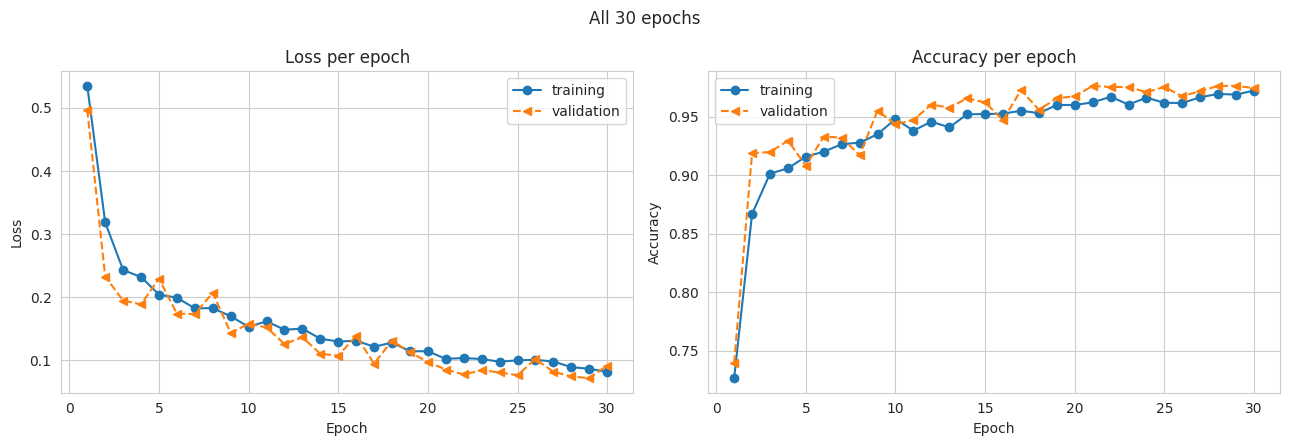

In [18]:
# Training resumes where it stopped for a few more epochs, and the two histories
# are joined into one
start = time.time()
more = mask_cnn.fit(ds_train,
                    validation_data=ds_valid,
                    initial_epoch=FIRST_EPOCHS,
                    epochs=FIRST_EPOCHS + EXTRA_EPOCHS,
                    verbose=2)
print('Training took %.1f minutes.' % ((time.time() - start) / 60))

full_history = {key: history.history[key] + more.history[key]
                for key in history.history}
plot_history(full_history, 'All %d epochs' % (FIRST_EPOCHS + EXTRA_EPOCHS))

The network keeps its weights between the two calls, so the second one continues
from epoch 21 instead of starting over, and the plot joins both rounds into one
pair of curves.

The extra epochs paid off. The training loss keeps falling, from 0.1143 at epoch
20 to 0.0815 at epoch 30, and the validation accuracy settles around 0.97, with a
mean of 0.9739 over the last ten epochs and a best of 0.9762. The lowest
validation loss, 0.0718, comes at epoch 29. The last epoch rises to 0.0916, a
single bump like the one at epoch 26, while the training loss is still falling,
so the curves are close to flat by the end and stopping here loses little.

## Evaluation (CRISP-DM 5)

The test photographs have not been seen by the network nor used to decide
anything about it, so their scores are the estimate of how it would do on new
faces.

In [19]:
# The test photographs get the central crop, the same as validation
x_test_ready = preprocess(x_test, mode='eval')

# Logits of the test photographs, turned into probabilities and classes
test_logits = mask_cnn.predict(x_test_ready, batch_size=BATCH_SIZE, verbose=0).ravel()
test_probability = expit(test_logits)
test_predicted = (test_logits > LOGIT_THRESHOLD).astype(int)

test_loss, test_accuracy = mask_cnn.evaluate(x_test_ready, y_test.astype(np.float32),
                                             batch_size=BATCH_SIZE, verbose=0)
majority_share = max(y_test.mean(), 1 - y_test.mean())
print('Test loss:     %.4f' % test_loss)
print('Test accuracy: %.4f' % accuracy_score(y_test, test_predicted))
print('Accuracy of always answering the larger class: %.4f' % majority_share)
print()
print(classification_report(y_test, test_predicted, target_names=CLASS_NAMES,
                            digits=4))

Test loss:     0.1463
Test accuracy: 0.9532
Accuracy of always answering the larger class: 0.5066

              precision    recall  f1-score   support

without mask     0.9484    0.9599    0.9541       574
   with mask     0.9583    0.9463    0.9523       559

    accuracy                         0.9532      1133
   macro avg     0.9533    0.9531    0.9532      1133
weighted avg     0.9533    0.9532    0.9532      1133



The accuracy is the share of test photographs classified correctly, and the line
below it is the floor any model has to beat: the accuracy of always answering the
larger class without looking at the picture. In the report, precision is, of the
photographs the network put in a class, the share that truly belong to it.
Recall is, of the photographs that truly belong to a class, the share the network
found. The f1-score combines both into one number, and support is how many test
photographs each class has.

The network classifies 95.32 percent of the test photographs correctly, against
50.66 percent for the floor, and its test loss is 0.1463. The two classes are
handled almost equally. It finds 95.99 percent of the uncovered faces and 94.63
percent of the covered ones, and when it says mask it is right 95.83 percent of
the time. The small difference leans toward answering without mask when in
doubt.

The test score is lower than the last validation score, 0.9532 against 0.9744,
and the test loss is higher, 0.1463 against 0.0916. Both parts have the same size
and the same class mix, so the gap is about twenty four photographs that happened
to be harder in the test part. Validation was also looked at after every epoch to
decide whether to keep training, while the test part was used only here, which is
exactly why the test number is the one to report.

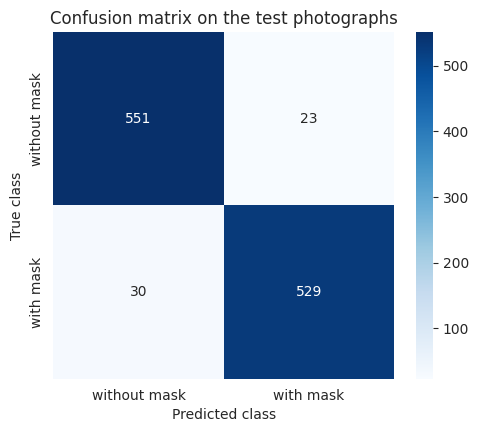

In [20]:
# Confusion matrix of the test photographs
matrix = confusion_matrix(y_test, test_predicted)
plt.figure(figsize=(5.5, 4.5))
sns.heatmap(matrix, annot=True, fmt='d', cmap='Blues',
            xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES)
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.title('Confusion matrix on the test photographs')
plt.show()

Each row of the matrix is a true class and each column a predicted one, so the
diagonal holds the correct answers and the two cells off it the two kinds of
mistake. The top right cell counts uncovered faces taken as covered, the mistake
that would let someone through without a mask, and the bottom left one counts
covered faces taken as uncovered.

Of the 1133 test photographs, 551 uncovered and 529 covered faces are right. Of
the 53 mistakes, 30 are covered faces taken as uncovered and 23 uncovered faces
taken as covered. For a camera at a door the second kind is the dangerous one,
since it lets someone in without a mask, and it happens to 23 of 574 uncovered
faces, 4.0 percent. The first kind would mostly mean stopping someone who is
already wearing a mask, an annoyance rather than a risk.

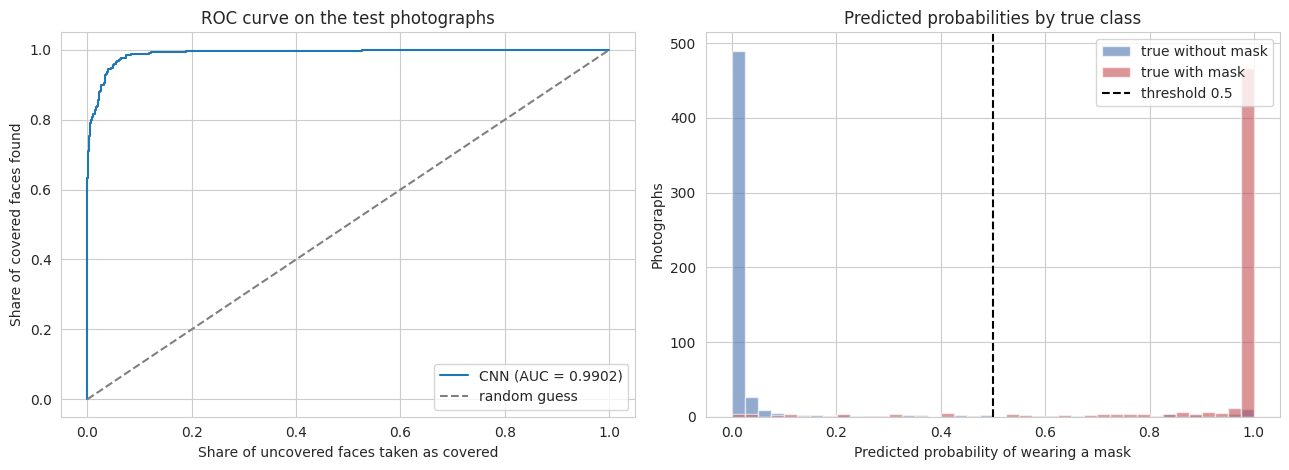

Area under the ROC curve: 0.9902


In [21]:
# ROC curve and the distribution of the predicted probabilities
false_rate, true_rate, _ = roc_curve(y_test, test_probability)
auc = roc_auc_score(y_test, test_probability)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
axes[0].plot(false_rate, true_rate, label='CNN (AUC = %.4f)' % auc)
axes[0].plot([0, 1], [0, 1], linestyle='--', color='grey', label='random guess')
axes[0].set_xlabel('Share of uncovered faces taken as covered')
axes[0].set_ylabel('Share of covered faces found')
axes[0].set_title('ROC curve on the test photographs')
axes[0].legend()

for label, colour in zip([0, 1], ['#4c72b0', '#c44e52']):
    axes[1].hist(test_probability[y_test == label], bins=40, alpha=0.6,
                 color=colour, label='true ' + CLASS_NAMES[label])
axes[1].axvline(0.5, color='black', linestyle='--', label='threshold 0.5')
axes[1].set_xlabel('Predicted probability of wearing a mask')
axes[1].set_ylabel('Photographs')
axes[1].set_title('Predicted probabilities by true class')
axes[1].legend()
plt.tight_layout()
plt.show()
print('Area under the ROC curve: %.4f' % auc)

The ROC curve moves the threshold from 1 down to 0 and draws, for each value, the
share of covered faces found against the share of uncovered faces wrongly taken
as covered. A perfect model goes straight up to the top left corner and the
dashed diagonal is a coin toss. The area under the curve, AUC, sums it up in one
number from 0.5 for a coin toss to 1 for a perfect separation, and it can be read
as the chance that a random covered face gets a higher probability than a random
uncovered one. The histogram shows the predicted probability of every test
photograph, coloured by its true class, with the threshold of 0.5 as a dashed
line. Bars far from the line are confident answers, and bars of one colour on the
wrong side of the line are the mistakes.

The curve hugs the top left corner and the area under it is 0.9902, so in 99 of
100 pairs of one covered and one uncovered test face the covered one gets the
higher probability. The histogram explains why the accuracy is lower than that
number suggests. Nearly all the uncovered faces pile up at 0 and nearly all the
covered ones at 1, so most answers are confident, but a thin trail of bars of
both colours runs across the whole range, and a few red bars sit near 0, covered
faces the network was sure had no mask. Those confident mistakes are what a
different threshold could not fix.

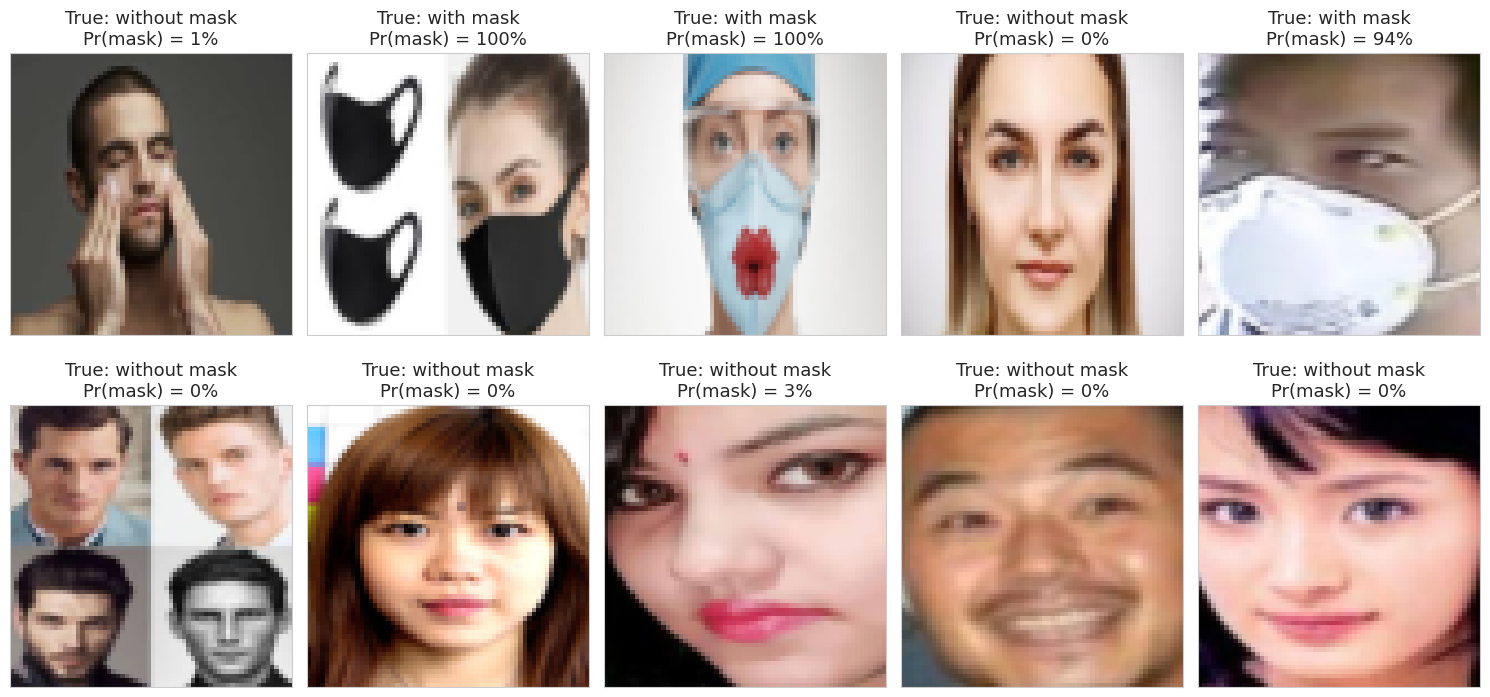

In [22]:
# The first ten test photographs with their true class and the probability of
# wearing a mask the network gave them
fig, axes = plt.subplots(2, 5, figsize=(15, 7.5))
for position, ax in enumerate(axes.ravel()):
    ax.imshow(x_test_ready[position])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.set_title('True: %s\nPr(mask) = %.0f%%'
                 % (CLASS_NAMES[y_test[position]], 100 * test_probability[position]),
                 size=13)
plt.tight_layout()
plt.show()

Each picture is one of the first ten test photographs, as the network received
it, with its true class and the probability of wearing a mask the network gave
it. A value close to 100 percent under a covered face, or close to 0 under an
uncovered one, is a confident right answer.

All ten are right. Nine of them are within 3 points of 0 or 100 percent, and the
least sure is the man with a white respirator, still at 94 percent. They include
a product shot with two masks beside a covered face, a surgical mask with an odd
red mark, and a collage of four uncovered faces, so the network copes with
pictures that are not a single centred face.

Wrong answers: 53 of 1133


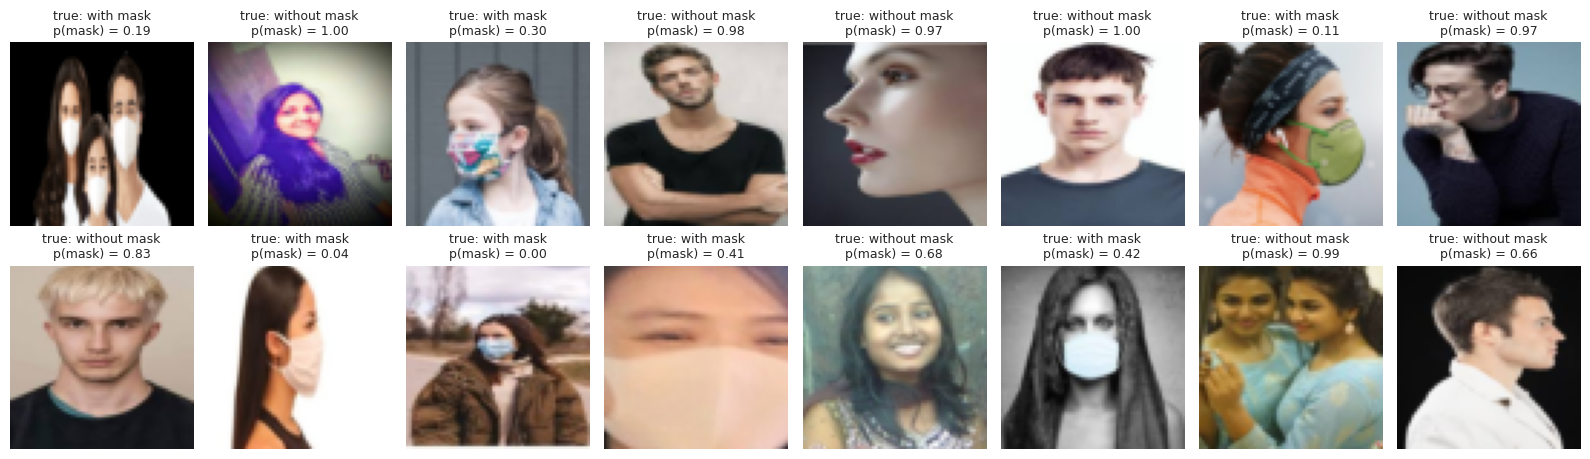

In [23]:
# The test photographs the network got wrong, with the probability it gave
wrong = np.flatnonzero(test_predicted != y_test)
print('Wrong answers:', len(wrong), 'of', len(y_test))

shown = wrong[:16]
if len(shown) > 0:
    columns = 8
    rows = int(np.ceil(len(shown) / columns))
    fig, axes = plt.subplots(rows, columns, figsize=(16, 2.4 * rows),
                             squeeze=False)
    for ax in axes.ravel():
        ax.axis('off')
    for ax, position in zip(axes.ravel(), shown):
        ax.imshow(x_test_ready[position])
        ax.set_title('true: %s\np(mask) = %.2f'
                     % (CLASS_NAMES[y_test[position]], test_probability[position]),
                     fontsize=9)
    plt.tight_layout()
    plt.show()

Each picture is a test photograph the network classified wrongly, at the size it
saw it, with its true class and the probability of wearing a mask the network
gave it. A probability near 0.5 is a doubtful case, and one near 0 or 1 is a
confident mistake.

The grid shows 16 of the 53 mistakes and most of them repeat a few situations.
Faces seen from the side are the most common, both covered ones the network
missed, such as the profile with a light mask at 0.04, and uncovered ones it took
as covered, such as the profile with red lips at 0.97 and the man in a white
jacket at 0.66. A mask close to the colour of skin, as in the beige close-up at
0.41, and small faces in a busy scene, as in the street photograph at 0.00 or the
family of three at 0.19, are the other frequent ones. Something held near the
mouth also misleads it, as with the man resting his hand on his chin at 0.97 and
the two women holding an object to their faces at 0.99.

Not every mistake has a visible cause. The young man in a dark t-shirt, an
uncovered face looking straight at the camera, gets 1.00, and the blond man at the
start of the bottom row gets 0.83. Those confident mistakes on plain frontal faces fit
the warning from the exploration: the network may have learned traits of the
pictures that come with the source of each class, not only the mask.

## Results (CRISP-DM 6: Deployment)

The trained network is saved to a file and loaded back, the way it would be
deployed at the entrance of a building, and the loaded copy classifies a
photograph read straight from disk.

Saved and reloaded mask_cnn.keras (4.5 MB)
without_mask_300.jpg -> without mask with p(mask) = 0.0033
with_mask_408.jpg -> with mask with p(mask) = 0.8784


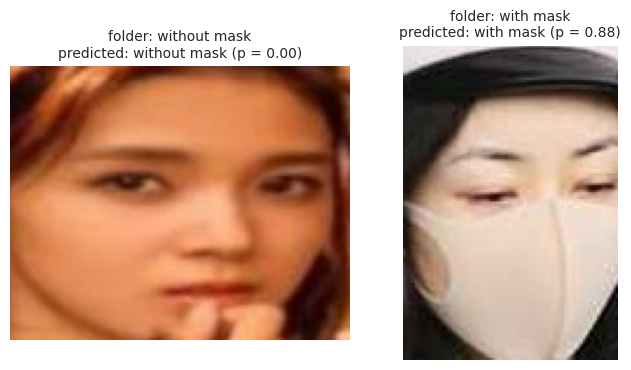

In [24]:
# Save the trained network and load it back
mask_cnn.save(MODEL_FILE)
loaded_cnn = keras.models.load_model(MODEL_FILE)
print('Saved and reloaded', MODEL_FILE,
      '(%.1f MB)' % (os.path.getsize(MODEL_FILE) / 1024 ** 2))


# Classify one file with the loaded network
def predict_mask(path, model):
    """Return the predicted class and the probability of wearing a mask."""
    batch = preprocess(load_image(path)[np.newaxis], mode='eval')
    logit = float(model.predict(batch, verbose=0)[0, 0])
    probability = float(expit(logit))
    return CLASS_NAMES[int(logit > LOGIT_THRESHOLD)], probability


# One photograph of each class, read from its file
fig, axes = plt.subplots(1, 2, figsize=(7, 3.8))
for ax, folder in zip(axes, CLASS_FOLDERS):
    path = faces[faces['folder'] == folder].sample(1, random_state=RANDOM_STATE + 1)['path'].iloc[0]
    predicted, probability = predict_mask(path, loaded_cnn)
    with Image.open(path) as handle:
        ax.imshow(handle.convert('RGB'))
    ax.set_title('folder: %s\npredicted: %s (p = %.2f)'
                 % (folder.replace('_', ' '), predicted, probability), fontsize=10)
    ax.axis('off')
    print(os.path.basename(path), '->', predicted, 'with p(mask) = %.4f' % probability)
plt.tight_layout()
plt.show()

The size printed is the file that would be copied to the camera, and each picture
is shown at its original size with the folder it came from and the answer of the
reloaded network.

The saved network takes 4.5 MB and the copy loaded back from disk works: it gives
the uncovered face a probability of wearing a mask of 0.0033 and the covered one
0.8784, both on the right side of 0.5. The second answer is less sure than most,
which fits the mistakes above, since its mask is a light colour close to the skin.
These two files were drawn from the whole collection, so they may have been part
of the training photographs. The cell checks that the saved model loads and
predicts, and the evaluation of how well it predicts is the test section above.

### Conclusions

The model is a convolutional neural network of four convolutional blocks with
32, 64, 128 and 256 kernels of 3 x 3, max pooling, dropout and global average
pooling, ending in a single neuron that gives the logit of wearing a mask. It
learns 388673 parameters from 5287 photographs, with random crops and flips as
data augmentation, over 30 epochs.

On 1133 test photographs it never saw it is right 95.32 percent of the time,
against 50.66 percent for always answering the larger class, and its area under
the ROC curve is 0.9902. It lets 23 of 574 uncovered faces through as covered,
4.0 percent, and stops 30 of 559 covered faces as uncovered, 5.4 percent. The
training and validation curves fell together through the 30 epochs with no sign
of overfitting.

Its use is recommended as a screening aid, for example a camera that asks a
person to put on a mask, as long as a person reviews the doubtful cases. It is
not reliable enough to act alone. About one face in twenty one is misclassified,
and the mistakes cluster in faces seen from the side, small faces in busy
scenes, masks close to the colour of skin and objects held near the mouth, with a
few confident mistakes on plain frontal faces that have no visible cause.

The limitations follow from the data. The photographs are mostly faces looking
at the camera, so profiles are underrepresented. The two classes were collected
from sources that differ in file size, sharpness and background, as the size
scatter and the average photographs showed, so part of what the network learned
may be those traits rather than the mask, and a test on photographs from a new
source, such as the actual camera at a door, is needed before trusting it there.
Finally, the test score is about 2.1 points below the last validation score,
which shows that a single split of this size still moves the estimate by a
couple of points, and the 95.32 percent should be read with that margin in mind.